In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [17]:
path = "../data/clean"
df = pd.read_csv(f'{path}/appointments_merged.csv')

In [18]:
df.head()

,appointment_id,patient_id,provider_id,facility_id,payer_id,calendar_date,appointment_month,appointment_day,appointment_weekday,appointment_hour,...,facility_zip_area_id,urban_rural_group,teaching_site_flag,service_line_focus,payer_group,calendar_year,calendar_quarter,weekend_flag,holiday_flag,flu_season_flag
0,APT000126,RBP011885,RBPV0067,SP03,PAY06,2024-01-01,1,1,1,8,...,ZA015,Urban core,1,Behavioral health,Exchange,2024,1,0,1,1
1,APT010570,RBP005811,RBPV0014,PC03,PAY02,2024-01-01,1,1,1,8,...,ZA025,Suburban,0,Primary care,Commercial,2024,1,0,1,1
2,APT010617,RBP010074,RBPV0105,UC02,PAY04,2024-01-01,1,1,1,8,...,ZA058,Small town,0,Urgent care,Medicare,2024,1,0,1,1
3,APT027760,RBP011255,RBPV0025,PC03,PAY01,2024-01-01,1,1,1,8,...,ZA025,Suburban,0,Primary care,Commercial,2024,1,0,1,1
4,APT032568,RBP006231,RBPV0011,PC03,PAY02,2024-01-01,1,1,1,9,...,ZA025,Suburban,0,Primary care,Commercial,2024,1,0,1,1


In [19]:
# wait_to_room_minutes uses -1 as a placeholder for "patient never roomed"
df["wait_to_room_minutes"] = df["wait_to_room_minutes"].replace(-1, np.nan)

In [20]:
# one outcome column: Completed / Cancelled / No-show
df["outcome"] = np.select(
    [df["no_show_flag"] == 1, df["cancel_flag"] == 1],
    ["No-show", "Cancelled"],
    default="Completed",
)

In [21]:
OVERALL = df["no_show_flag"].mean()
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.05)
PCT = lambda v, _=None: f"{v:.0%}"


def finish(fig, name):
    fig.tight_layout()
    # fig.savefig(OUT / name, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    # print("saved", name)


def baseline(ax, horizontal=True):
    """Dashed line at the overall no-show rate."""
    (ax.axhline if horizontal else ax.axvline)(
        OVERALL, color="grey", ls="--", lw=1, label=f"Overall {OVERALL:.1%}"
    )


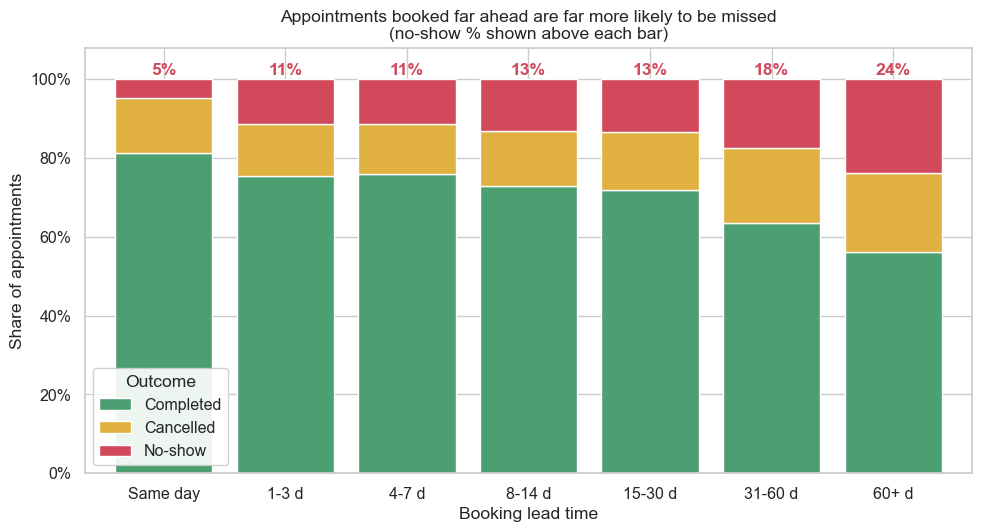

In [22]:
# 1. Lead time -> outcome mix
bins = [-1, 0, 3, 7, 14, 30, 60, 10_000]
labels = ["Same day", "1-3 d", "4-7 d", "8-14 d", "15-30 d", "31-60 d", "60+ d"]
df["lead_bin"] = pd.cut(df["lead_days"], bins=bins, labels=labels)

mix = (
    df.groupby("lead_bin", observed=True)["outcome"]
    .value_counts(normalize=True)
    .unstack()[["Completed", "Cancelled", "No-show"]]
)
fig, ax = plt.subplots(figsize=(10, 5.5))
mix.plot(kind="bar", stacked=True, ax=ax, color=["#4C9F70", "#E0B040", "#D1495B"], width=0.8)
for i, v in enumerate(mix["No-show"]):
    ax.text(i, 1.01, f"{v:.0%}", ha="center", color="#D1495B", fontweight="bold")
ax.yaxis.set_major_formatter(PCT)
ax.set_ylim(0, 1.08)
ax.set_xlabel("Booking lead time")
ax.set_ylabel("Share of appointments")
ax.set_title("Appointments booked far ahead are far more likely to be missed\n(no-show % shown above each bar)")
ax.legend(title="Outcome", loc="lower left", framealpha=0.9)
plt.setp(ax.get_xticklabels(), rotation=0)
finish(fig, "01_lead_time_outcome_mix.png")

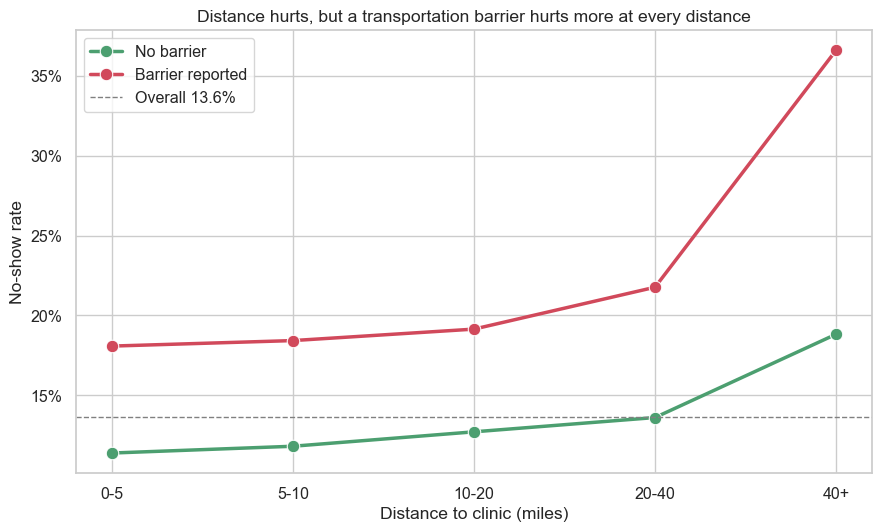

In [23]:
# 2. Distance x transportation barrier -> no-show
df["dist_bin"] = pd.cut(
    df["distance_to_clinic_miles"],
    [0, 5, 10, 20, 40, 1000],
    labels=["0-5", "5-10", "10-20", "20-40", "40+"],
)
t = (
    df.groupby(["dist_bin", "transportation_barrier_flag"], observed=True)["no_show_flag"]
    .agg(rate="mean", n="size")
    .reset_index()
)
t["Transportation barrier"] = t["transportation_barrier_flag"].map({0: "No barrier", 1: "Barrier reported"})
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.lineplot(data=t, x="dist_bin", y="rate", hue="Transportation barrier", marker="o",
             markersize=9, linewidth=2.5, palette=["#4C9F70", "#D1495B"], ax=ax)
baseline(ax)
ax.yaxis.set_major_formatter(PCT)
ax.set_xlabel("Distance to clinic (miles)")
ax.set_ylabel("No-show rate")
ax.set_title("Distance hurts, but a transportation barrier hurts more at every distance")
ax.legend()
finish(fig, "02_distance_transport_barrier.png")

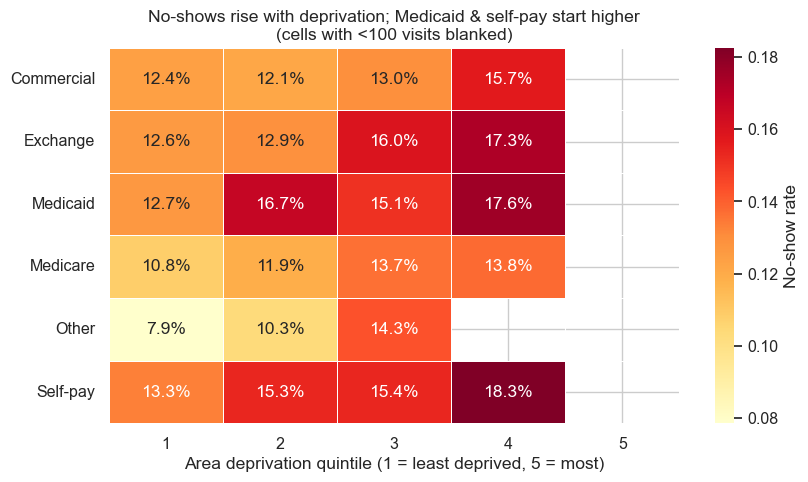

In [24]:
# 3. Deprivation quintile x payer group (no-show heatmap)
piv = df.pivot_table(index="payer_group", columns="deprivation_quintile",
                     values="no_show_flag", aggfunc="mean")
cnt = df.pivot_table(index="payer_group", columns="deprivation_quintile",
                     values="no_show_flag", aggfunc="size")
piv = piv.where(cnt >= 100)  # hide cells with too few appointments to trust
fig, ax = plt.subplots(figsize=(8.5, 5))
sns.heatmap(piv, annot=True, fmt=".1%", cmap="YlOrRd", linewidths=0.5,
            cbar_kws={"label": "No-show rate"}, ax=ax)
ax.set_xlabel("Area deprivation quintile (1 = least deprived, 5 = most)")
ax.set_ylabel("")
ax.set_title("No-shows rise with deprivation; Medicaid & self-pay start higher\n(cells with <100 visits blanked)")
finish(fig, "03_deprivation_by_payer_heatmap.png")

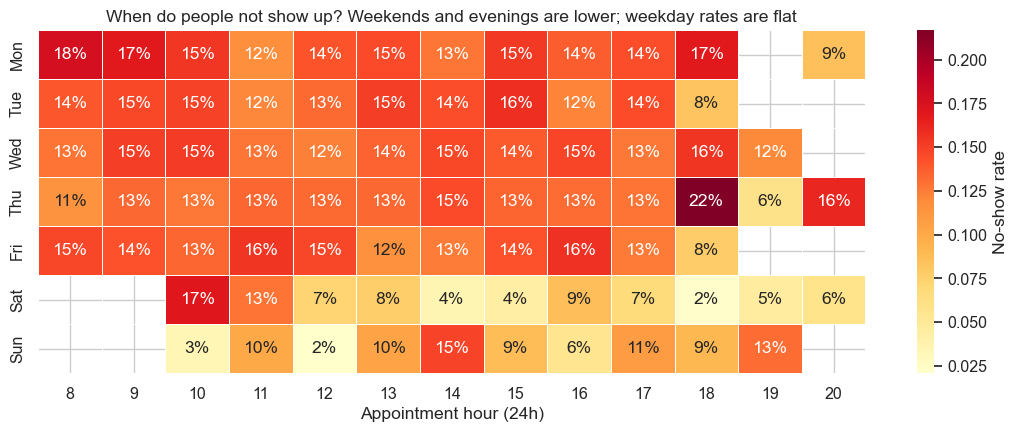

In [25]:
# 4. Weekday x hour no-show heatmap
day_names = {1: "Mon", 2: "Tue", 3: "Wed", 4: "Thu", 5: "Fri", 6: "Sat", 7: "Sun"}
wh = df.pivot_table(index="appointment_weekday", columns="appointment_hour",
                    values="no_show_flag", aggfunc="mean")
wh_n = df.pivot_table(index="appointment_weekday", columns="appointment_hour",
                      values="no_show_flag", aggfunc="size")
wh = wh.where(wh_n >= 30)
wh.index = [day_names[i] for i in wh.index]
fig, ax = plt.subplots(figsize=(11, 4.5))
sns.heatmap(wh, annot=True, fmt=".0%", cmap="YlOrRd", linewidths=0.5,
            cbar_kws={"label": "No-show rate"}, ax=ax)
ax.set_xlabel("Appointment hour (24h)")
ax.set_ylabel("")
ax.set_title("When do people not show up? Weekends and evenings are lower; weekday rates are flat")
finish(fig, "04_weekday_hour_heatmap.png")

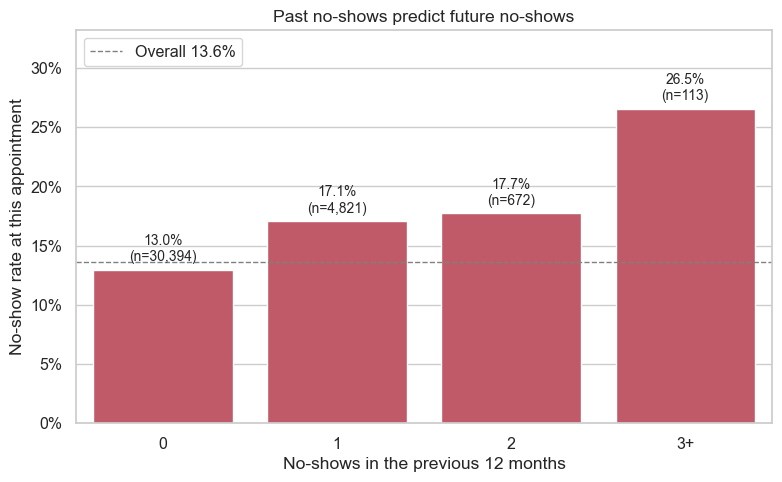

In [26]:
# 5. Prior no-show history -> next no-show rate
h = df.assign(prior=df["prior_no_show_count_12m"].clip(upper=3))
h = h.groupby("prior")["no_show_flag"].agg(rate="mean", n="size").reset_index()
h["prior"] = h["prior"].map({0: "0", 1: "1", 2: "2", 3: "3+"})
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=h, x="prior", y="rate", color="#D1495B", ax=ax)
baseline(ax)
for i, r in h.iterrows():
    ax.text(i, r["rate"] + 0.005, f"{r['rate']:.1%}\n(n={r['n']:,})", ha="center", va="bottom", fontsize=10)
ax.yaxis.set_major_formatter(PCT)
ax.set_ylim(0, h["rate"].max() * 1.25)
ax.set_xlabel("No-shows in the previous 12 months")
ax.set_ylabel("No-show rate at this appointment")
ax.set_title("Past no-shows predict future no-shows")
ax.legend(loc="upper left")
finish(fig, "05_prior_no_show_history.png")

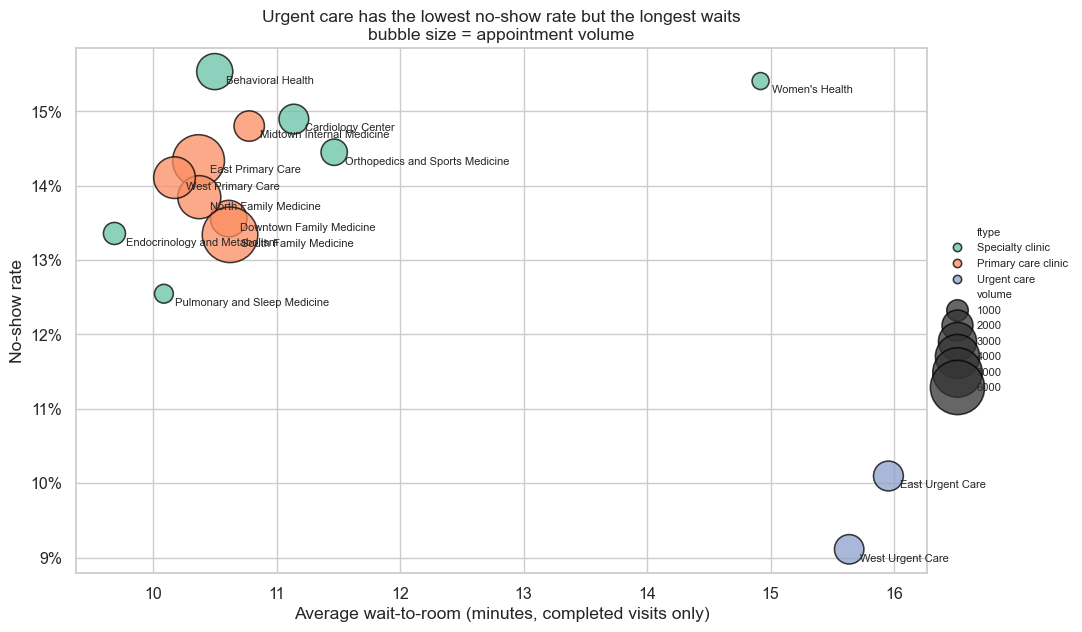

In [27]:
# 6. Facility: no-show rate vs wait time (bubble = volume)
fac = (
    df.groupby("facility_name")
    .agg(no_show=("no_show_flag", "mean"),
         wait=("wait_to_room_minutes", "mean"),   # attended visits only
         volume=("appointment_id", "size"),
         ftype=("facility_type", "first"))
    .reset_index()
)
fac["label"] = fac["facility_name"].str.replace("Riverbend ", "", regex=False)
fig, ax = plt.subplots(figsize=(11, 6.5))
sns.scatterplot(data=fac, x="wait", y="no_show", size="volume", hue="ftype",
                sizes=(150, 1600), alpha=0.75, palette="Set2", edgecolor="black", ax=ax)
for _, r in fac.iterrows():
    ax.annotate(r["label"], (r["wait"], r["no_show"]), xytext=(8, -3),
                textcoords="offset points", fontsize=8, va="top")
ax.yaxis.set_major_formatter(PCT)
ax.set_xlabel("Average wait-to-room (minutes, completed visits only)")
ax.set_ylabel("No-show rate")
ax.set_title("Urgent care has the lowest no-show rate but the longest waits\nbubble size = appointment volume")
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=8, frameon=False)
finish(fig, "06_facility_wait_vs_noshow.png")

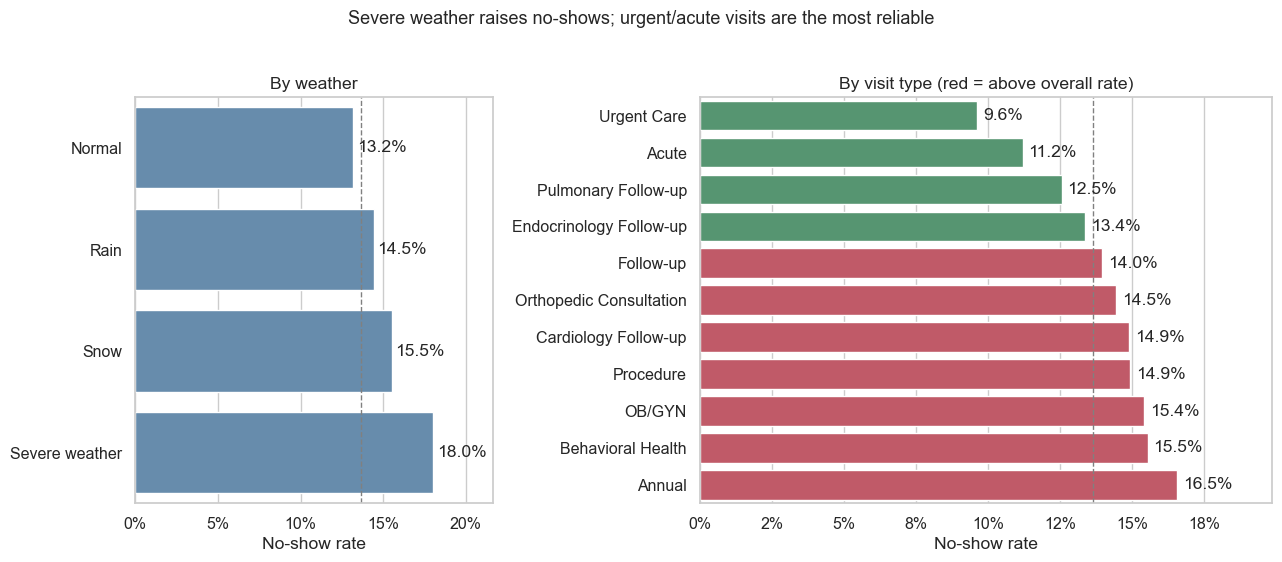

In [28]:
# 7. Weather & visit type -> no-show (ranked)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), gridspec_kw={"width_ratios": [1, 1.6]})
w = df.groupby("weather_severity_group")["no_show_flag"].mean().sort_values()
sns.barplot(x=w.values, y=w.index, color="#5B8DB8", ax=axes[0])
axes[0].axvline(OVERALL, color="grey", ls="--", lw=1)
for i, v in enumerate(w.values):
    axes[0].text(v + 0.002, i, f"{v:.1%}", va="center")
axes[0].set_title("By weather")
axes[0].set_xlabel("No-show rate"); axes[0].set_ylabel("")
axes[0].xaxis.set_major_formatter(PCT)
axes[0].set_xlim(0, w.max() * 1.2)

vt = df.groupby("visit_type")["no_show_flag"].mean().sort_values()
colors = ["#D1495B" if v > OVERALL else "#4C9F70" for v in vt.values]
sns.barplot(x=vt.values, y=vt.index, palette=colors, hue=vt.index, legend=False, ax=axes[1])
axes[1].axvline(OVERALL, color="grey", ls="--", lw=1)
for i, v in enumerate(vt.values):
    axes[1].text(v + 0.002, i, f"{v:.1%}", va="center")
axes[1].set_title("By visit type (red = above overall rate)")
axes[1].set_xlabel("No-show rate"); axes[1].set_ylabel("")
axes[1].xaxis.set_major_formatter(PCT)
axes[1].set_xlim(0, vt.max() * 1.2)
fig.suptitle("Severe weather raises no-shows; urgent/acute visits are the most reliable", y=1.02, fontsize=13)
finish(fig, "07_weather_and_visit_type.png")

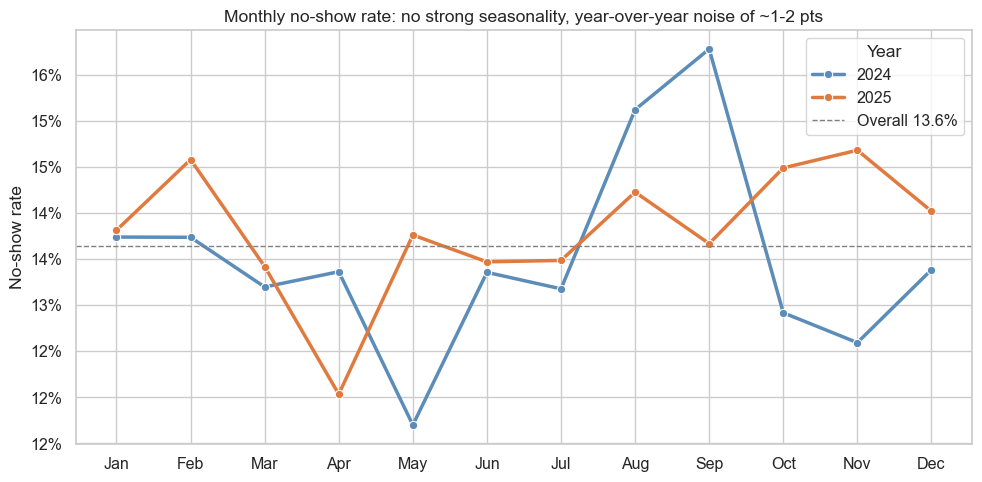

In [29]:
# 8. Monthly no-show trend, 2024 vs 2025
m = (
    df.groupby(["calendar_year", "appointment_month"])["no_show_flag"]
    .mean().reset_index()
)
fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(data=m, x="appointment_month", y="no_show_flag", hue="calendar_year",
             marker="o", linewidth=2.5, palette=["#5B8DB8", "#E07A3F"], ax=ax)
baseline(ax)
ax.set_xticks(range(1, 13))
ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.yaxis.set_major_formatter(PCT)
ax.set_xlabel("")
ax.set_ylabel("No-show rate")
ax.set_title("Monthly no-show rate: no strong seasonality, year-over-year noise of ~1-2 pts")
ax.legend(title="Year")
finish(fig, "08_monthly_trend_by_year.png")